In [5]:
# Uncomment when importing from GitHub
# !git clone https://www.github.com/simoneroncallo/quantum-optical-neuron.git
# %cd /content/quantum-optical-neuron
# !mkdir ./output/data

# Uncomment when importing from Google Drive
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/'Colab Notebooks'/quantum-optical-neuron-main

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/quantum-optical-neuron-main


In [6]:
import sys

# Uncomment when importing from GitHub
# dir = '/content/quantum-optical-neuron'

# Uncomment when importing from Google Drive
dir = '/content/drive/MyDrive/"Colab Notebooks"/quantum-optical-neuron-main'

sys.path.append(dir)
from qon import spatial_loss_derivative, Fourier_loss_derivative
from qon import optimization

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from keras import layers, models, activations, optimizers
from keras.datasets import mnist
from keras.utils import set_random_seed

In [8]:
# Set the seeds
np.random.seed(2024)
set_random_seed(2024)

In [15]:
# Hyperparameters
numEpochs = 300
learningRateWeights = 0.075
learningRateBias = 0.005
numTrainImgs = None # Load the full dataset with "None"
numShots = -1 # Deactivate noise with "-1"

# Dataset
We use the MNIST dataset, which contains $28 \times 28$ images of handwritten digits from $0$ to $9$. We guarantee a fair comparison by increasing the MNIST resolution to $32 \times 32$ pixels (separately padding each image of the dataset). We train  the models to distinguish among images of *zeros* and *ones*.

After normalization, each element of the dataset is identified with the corrisponding amplitudes of quantum optical neuron input state, bypassing the simulation of the imaging apparatus.

In [16]:
# Load the MNIST dataset
(trainImgs, trainLabels), (testImgs, testLabels) = mnist.load_data()

# Filter 0 and 1 from the dataset
train0s, test0s = np.where(trainLabels == 0), np.where(testLabels == 0)
train1s, test1s = np.where(trainLabels == 1), np.where(testLabels == 1)

train0sImgs = trainImgs[train0s[0]]
train1sImgs = trainImgs[train1s[0]]

test0sImgs = testImgs[test0s[0]]
test1sImgs = testImgs[test1s[0]]

trainImgs = np.concatenate((train0sImgs, train1sImgs), axis = 0)
testImgs = np.concatenate((test0sImgs, test1sImgs), axis = 0)

# Create the dataset of images and labels (0s and 1s)
train0Labels = np.zeros(train0sImgs.shape[0])
train1Labels = np.ones(train1sImgs.shape[0])
trainLabels = np.concatenate((train0Labels, train1Labels), axis = 0)

test0Labels = np.zeros(test0sImgs.shape[0])
test1Labels = np.ones(test1sImgs.shape[0])
testLabels = np.concatenate((test0Labels, test1Labels), axis = 0)

# Reshuffle images and labels consistently
idxs = np.arange(trainImgs.shape[0])
np.random.shuffle(idxs)

trainImgs = trainImgs[idxs]
trainLabels = trainLabels[idxs]

# Convert to float
trainImgs = trainImgs.astype(np.float64)
testImgs = testImgs.astype(np.float64)
trainLabels = trainLabels.astype(np.float64)
testLabels = testLabels.astype(np.float64)

# Identify each image with the single-photon discretized amplitudes
for idx, trainImg in enumerate(trainImgs):
  trainImgs[idx,:,:] = trainImg/np.sum(trainImg) # Normalization
for idx, testImg in enumerate(testImgs):
  testImgs[idx,:,:] = testImg/np.sum(testImg) # Normalization

# Amplitudes
trainImgs = np.sqrt(trainImgs[:,:,:])
testImgs = np.sqrt(testImgs[:,:,:])

# Padding from 28x28 to 32x32
trainImgs = np.pad(trainImgs, ((0,0),(2,2),(2,2)), mode='constant', \
                   constant_values = 0)
testImgs = np.pad(testImgs, ((0,0),(2,2),(2,2)), mode='constant', \
                   constant_values = 0)

# Reduce the training set
trainImgs = trainImgs[:numTrainImgs,:,:]
trainLabels = trainLabels[:numTrainImgs]

print('Training set has shape', trainImgs.shape)

Training set has shape (12665, 32, 32)


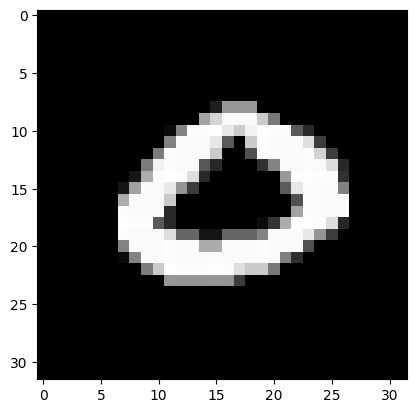

In [17]:
# Print example
idx = 10
plt.imshow(np.square(trainImgs[idx,:,:]))
plt.gray()
plt.show()

# <font color='ORANGE'>Simulation</font>
 We numerically compare the predictability of the quantum optical neuron against that of conventional neural network designs, constrained to the same number of parameters.

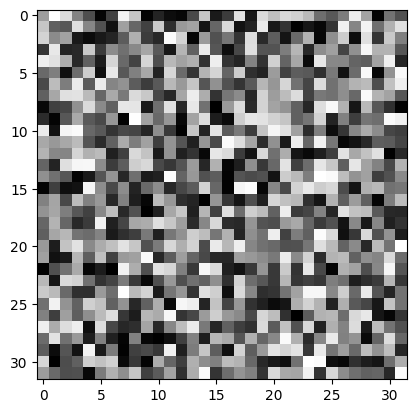

In [18]:
# Parameters random initialization
initial_weights = np.random.uniform(-1,1,(32,32)) # Uniform sampling
bias = 0

# Normalization
norm = np.sum(np.square(initial_weights))
weights = initial_weights/np.sqrt(norm)

plt.imshow(weights[:,:])
plt.gray()

In [19]:
# Training
weights, bias, loss_history, test_loss_history, accuracy_history,\
              test_accuracy_history = optimization(spatial_loss_derivative,\
                weights, bias, trainLabels, testLabels, trainImgs, testImgs,\
                  numEpochs, learningRateWeights, learningRateBias, numShots)

EPOCH 0
Loss 2.9274967673759016 Val_Loss 2.951013374769017
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 1
Loss 2.7571734745281327 Val_Loss 2.7791598961152384
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 2
Loss 2.5863910056810133 Val_Loss 2.606726951561041
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 3
Loss 2.413727445617264 Val_Loss 2.4321864827831163
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 4
Loss 2.235631290950443 Val_Loss 2.251784509784318
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 5
Loss 2.043815590089147 Val_Loss 2.0568520306231353
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 6
Loss 1.8203958243147649 Val_Loss 1.8288199813796944
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 7
Loss 1.5321885561539845 Val_Loss 1.5334871846832236
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 8
Loss 1.1413531101606722 Val_Lo

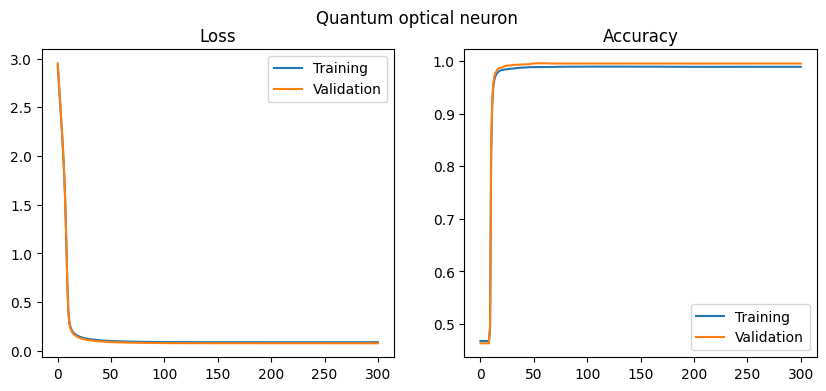

In [20]:
# History plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(loss_history, label = 'Training')
ax1.plot(test_loss_history, label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(accuracy_history, label = 'Training')
ax2.plot(test_accuracy_history, label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Quantum optical neuron')
plt.show()

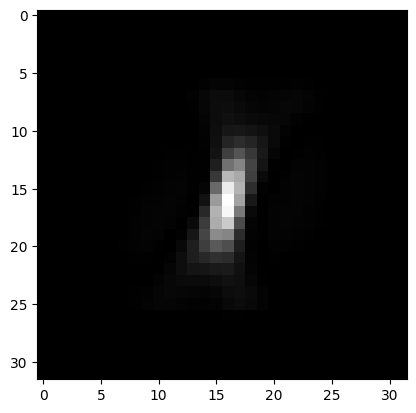

In [21]:
# Parameters plot
# Normalization
norm = np.sum(np.square(weights))
weights = weights/np.sqrt(norm)

probWeights = np.square(weights)

plt.imshow(probWeights)
plt.gray()

plt.show()

### Single neuron

In [22]:
model = models.Sequential()

model.add(layers.Flatten(input_shape=(32, 32, 1)))
model.add(layers.Dense(1, activation='sigmoid', use_bias=True))

model.build()
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
optimizer = optimizers.SGD(learning_rate = learningRateWeights)
model.compile(optimizer=optimizer, loss='binary_crossentropy', \
              metrics=['accuracy'])
dense_history = model.fit(trainImgs, trainLabels, \
                    batch_size = trainImgs.shape[0], \
                    epochs = numEpochs,
                    validation_data=(testImgs, testLabels))

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.7381 - loss: 0.6840 - val_accuracy: 0.8109 - val_loss: 0.6805
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.7983 - loss: 0.6809 - val_accuracy: 0.8615 - val_loss: 0.6774
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.8507 - loss: 0.6779 - val_accuracy: 0.8889 - val_loss: 0.6742
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.8865 - loss: 0.6748 - val_accuracy: 0.9158 - val_loss: 0.6711
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.9113 - loss: 0.6718 - val_accuracy: 0.9286 - val_loss: 0.6681
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9236 - loss: 0.6688 - val_accuracy: 0.9376 - val_loss: 0.6650
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.9330 - loss: 0.6658 - val_accuracy: 0.9433 - val_loss: 0.6620
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.9400 - loss: 0.6629 - val_accuracy: 0.9541 - val_

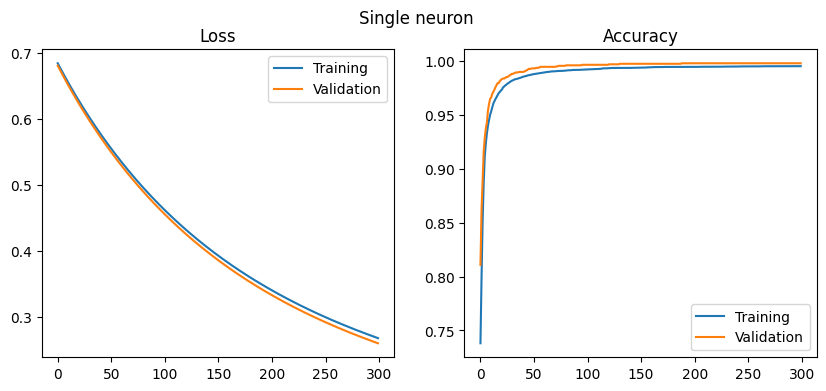

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(dense_history.history['loss'], label = 'Training')
ax1.plot(dense_history.history['val_loss'], label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(dense_history.history['accuracy'], label = 'Training')
ax2.plot(dense_history.history['val_accuracy'], label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Single neuron')
plt.show()

### Convolutional network

In [25]:
model = models.Sequential()

model.add(layers.Conv2D(10, (3, 3), activation='linear', use_bias=False, \
                        input_shape=(32, 32, 1)))
model.add(layers.Conv2D(4, (2, 2), activation='linear', use_bias=False))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Flatten())
model.add(layers.Dense(1, activation='sigmoid', use_bias=True))

model.build()
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 10)     │            90 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 4)      │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,035 (4.04 KB)

 Trainable params: 1,035 (4.04 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
optimizer = optimizers.SGD(learning_rate = learningRateWeights)
model.compile(optimizer=optimizer, loss='binary_crossentropy', \
              metrics=['accuracy'])
conv_history = model.fit(trainImgs, trainLabels, \
                    batch_size = trainImgs.shape[0], \
                    epochs = numEpochs,
                    validation_data=(testImgs, testLabels))

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step - accuracy: 0.3682 - loss: 0.6950 - val_accuracy: 0.3768 - val_loss: 0.6946
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.3979 - loss: 0.6944 - val_accuracy: 0.4128 - val_loss: 0.6940
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.4286 - loss: 0.6938 - val_accuracy: 0.4534 - val_loss: 0.6934
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.4598 - loss: 0.6932 - val_accuracy: 0.4856 - val_loss: 0.6927
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.4933 - loss: 0.6926 - val_accuracy: 0.5239 - val_loss: 0.6921
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - accuracy: 0.5171 - loss: 0.6920 - val_accuracy: 0.5404 - val_loss: 0.6915
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.5347 - loss: 0.6914 - val_accuracy: 0.5480 - val_loss: 0.6909
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5428 - loss: 0.6908 - val_accuracy: 0.5565 - val_

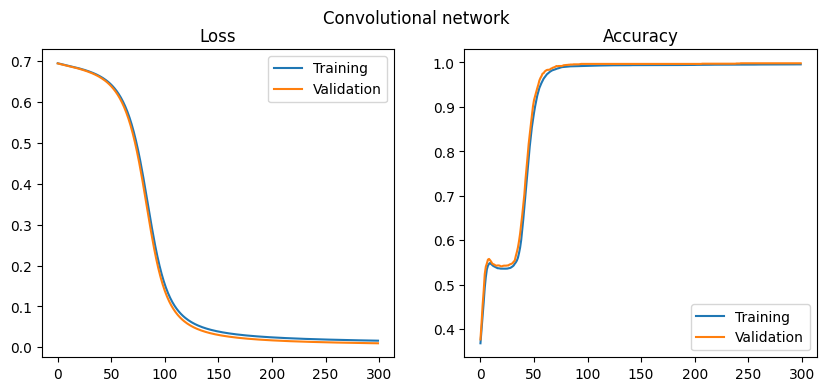

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(conv_history.history['loss'], label = 'Training')
ax1.plot(conv_history.history['val_loss'], label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(conv_history.history['accuracy'], label = 'Training')
ax2.plot(conv_history.history['val_accuracy'], label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Convolutional network')
plt.show()

## Comparison

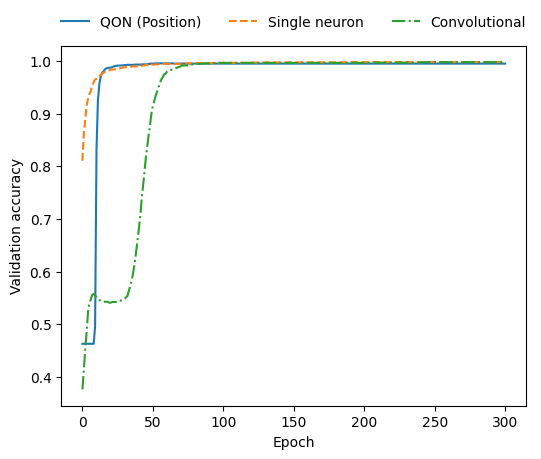

In [28]:
fig, ax1 = plt.subplots(figsize=(6, 5.5))

# Main plot
ax1.plot(test_accuracy_history, linestyle = '-', \
         label = 'QON (Position)')

ax1.plot(dense_history.history['val_accuracy'], linestyle = '--', \
         label = 'Single neuron')

ax1.plot(conv_history.history['val_accuracy'], linestyle = '-.', \
         label = 'Convolutional')

ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation accuracy')

pos = ax1.get_position()
ax1.set_position([pos.x0, pos.y0, pos.width, pos.height * 0.85])
ax1.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=3,
    frameon=False,
)

plt.show()

In [29]:
# Path ke folder output di dalam Google Drive
save_path = '/content/drive/MyDrive/Colab Notebooks/quantum-optical-neuron-main/output/data'

# Quantum optical neuron history
np.save(f'{save_path}/MNISTposition_OQPloss.npy', test_loss_history)
np.save(f'{save_path}/MNISTposition_OQPacc.npy', test_accuracy_history)

# Single neuron history
np.save(f'{save_path}/MNISTposition_MLPloss.npy', np.array(dense_history.history['val_loss']))
np.save(f'{save_path}/MNISTposition_MLPacc.npy', np.array(dense_history.history['val_accuracy']))

# Convolutional network history
np.save(f'{save_path}/MNISTposition_CONVloss.npy', np.array(conv_history.history['val_loss']))
np.save(f'{save_path}/MNISTposition_CONVacc.npy', np.array(conv_history.history['val_accuracy']))

# <font color='ORANGE'>Simulation</font> (Fourier encoding)
We repeat the same analysis and comparisons by encoding the dataset in the Fourier domain.

In [30]:
# Reinitialize the Tensorflow seed
set_random_seed(2024)

In [31]:
# Compute the fast Fourier transform
trainFourierImgs = np.zeros(trainImgs.shape, dtype = np.complex64)
testFourierImgs = np.zeros(testImgs.shape, dtype = np.complex64)

for idx, trainImg in enumerate(trainImgs):
  trainFourierImgs[idx,:,:] = np.transpose(np.fft.fftshift(\
                          np.fft.fft2(trainImgs[idx,:,:], norm = "ortho")))
  if idx < testImgs.shape[0]:
    testFourierImgs[idx,:,:] = np.transpose(np.fft.fftshift(\
                          np.fft.fft2(testImgs[idx,:,:],  norm = "ortho")))

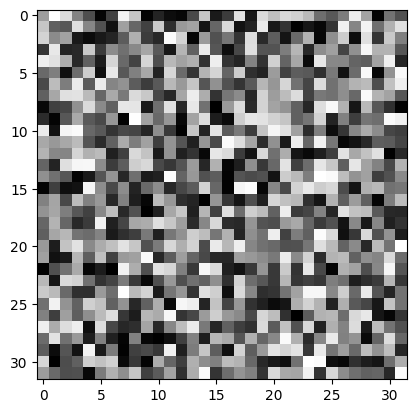

In [32]:
# Parameters reinizialization and normalization
bias = 0
norm = np.sum(np.square(initial_weights))
weights = initial_weights/np.sqrt(norm)

plt.imshow(weights[:,:])
plt.gray()

In [33]:
# Training
weights, bias, loss_history, test_loss_history, accuracy_history,\
        test_accuracy_history = optimization(Fourier_loss_derivative, weights,\
          bias, trainLabels, testLabels, trainFourierImgs, testFourierImgs,\
            numEpochs, learningRateWeights, learningRateBias, numShots)

EPOCH 0
Loss 2.928627273162428 Val_Loss 2.952451326322773
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 1
Loss 2.7616376773453193 Val_Loss 2.784026717246501
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 2
Loss 2.5942886073604976 Val_Loss 2.615248928206717
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 3
Loss 2.4276943789545307 Val_Loss 2.447220916010925
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 4
Loss 2.2621859766621544 Val_Loss 2.2802535998614957
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 5
Loss 2.0975635400737445 Val_Loss 2.114109983666376
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 6
Loss 1.9325231035980854 Val_Loss 1.947413130937231
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 7
Loss 1.7633457024773838 Val_Loss 1.776299073758969
Accuracy 0.46766679826292934 Val_Acc 0.46335697399527187
---
EPOCH 8
Loss 1.5813260893124357 Val_Loss

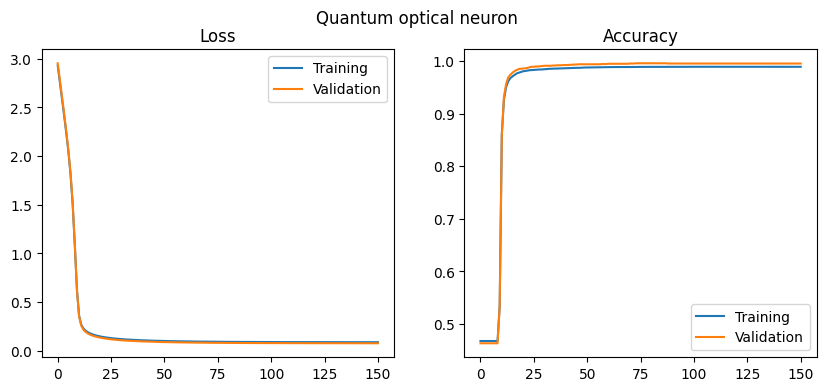

In [ ]:
# History plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(loss_history, label = 'Training')
ax1.plot(test_loss_history, label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(accuracy_history, label = 'Training')
ax2.plot(test_accuracy_history, label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Quantum optical neuron')
plt.show()

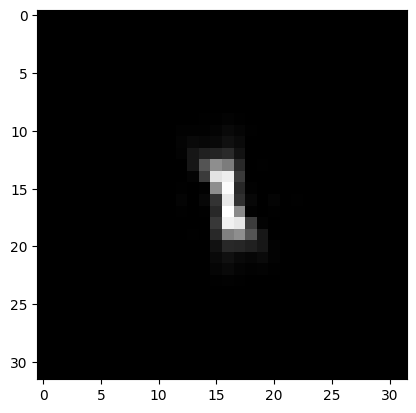

In [ ]:
# Parameters plot
# Normalization
norm = np.sum(np.square(weights))
weights = weights/np.sqrt(norm)

probWeights = np.square(weights)

plt.imshow(probWeights)
plt.gray()

plt.show()

### Single neuron

In [ ]:
model = models.Sequential()

model.add(layers.Flatten(input_shape=(32, 32, 1)))
model.add(layers.Dense(1, activation='sigmoid', use_bias=True))

model.build()
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = optimizers.SGD(learning_rate = learningRateWeights)
model.compile(optimizer=optimizer, loss='binary_crossentropy', \
              metrics=['accuracy'])
dense_history = model.fit(np.abs(trainFourierImgs), trainLabels, \
                    batch_size = trainImgs.shape[0], \
                    epochs = numEpochs,
                    validation_data=(np.abs(testFourierImgs), testLabels))

Epoch 1/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5323 - loss: 0.6955 - val_accuracy: 0.5366 - val_loss: 0.6946
Epoch 2/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.5323 - loss: 0.6948 - val_accuracy: 0.5366 - val_loss: 0.6939
Epoch 3/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.5323 - loss: 0.6940 - val_accuracy: 0.5366 - val_loss: 0.6931
Epoch 4/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.5323 - loss: 0.6933 - val_accuracy: 0.5366 - val_loss: 0.6924
Epoch 5/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.5323 - loss: 0.6926 - val_accuracy: 0.5366 - val_loss: 0.6916
Epoch 6/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - accuracy: 0.5323 - loss: 0.6918 - val_accuracy: 0.5366 - val_loss: 0.6909
Epoch 7/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.5323 - loss: 0.6911 - val_accuracy: 0.5366 - val_loss: 0.6902
Epoch 8/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.5323 - loss: 0.6904 - val_accuracy: 0.5366 - val_

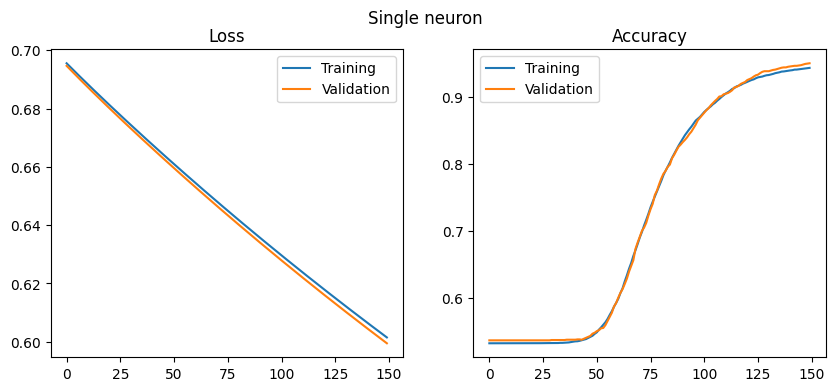

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(dense_history.history['loss'], label = 'Training')
ax1.plot(dense_history.history['val_loss'], label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(dense_history.history['accuracy'], label = 'Training')
ax2.plot(dense_history.history['val_accuracy'], label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Single neuron')
plt.show()

### Convolutional network

In [ ]:
model = models.Sequential()

model.add(layers.Conv2D(10, (3, 3), activation='linear', use_bias=False, \
                        input_shape=(32, 32, 1)))
model.add(layers.Conv2D(4, (2, 2), activation='linear', use_bias=False))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Flatten())
model.add(layers.Dense(1, activation='sigmoid', use_bias=True))

model.build()
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 10)     │            90 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 4)      │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,035 (4.04 KB)

 Trainable params: 1,035 (4.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = optimizers.SGD(learning_rate = learningRateWeights)
model.compile(optimizer=optimizer, loss='binary_crossentropy', \
              metrics=['accuracy'])
conv_history = model.fit(np.abs(trainFourierImgs), trainLabels, \
                    batch_size = trainImgs.shape[0], \
                    epochs = numEpochs,
                    validation_data=(np.abs(testFourierImgs), testLabels))

Epoch 1/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.4738 - loss: 0.6949 - val_accuracy: 0.4752 - val_loss: 0.6947
Epoch 2/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.4759 - loss: 0.6946 - val_accuracy: 0.4742 - val_loss: 0.6944
Epoch 3/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.4755 - loss: 0.6944 - val_accuracy: 0.4657 - val_loss: 0.6942
Epoch 4/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.4697 - loss: 0.6942 - val_accuracy: 0.4539 - val_loss: 0.6939
Epoch 5/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.4558 - loss: 0.6939 - val_accuracy: 0.4355 - val_loss: 0.6937
Epoch 6/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.4373 - loss: 0.6937 - val_accuracy: 0.4170 - val_loss: 0.6935
Epoch 7/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.4220 - loss: 0.6935 - val_accuracy: 0.4468 - val_loss: 0.6933
Epoch 8/150
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.4427 - loss: 0.6933 - val_accuracy: 0.5239 - val_

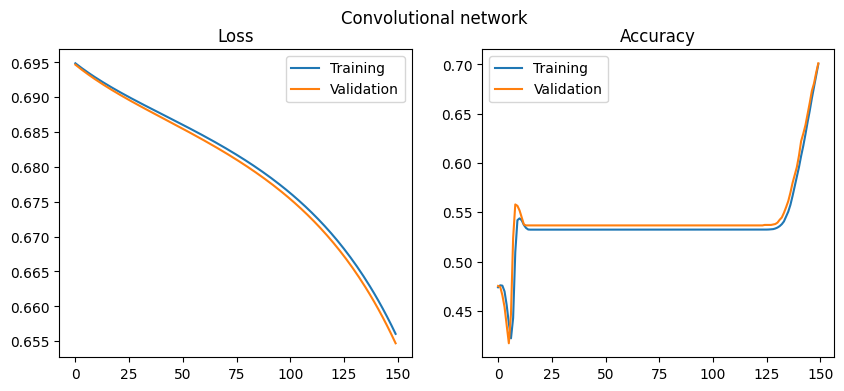

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(conv_history.history['loss'], label = 'Training')
ax1.plot(conv_history.history['val_loss'], label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(conv_history.history['accuracy'], label = 'Training')
ax2.plot(conv_history.history['val_accuracy'], label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Convolutional network')
plt.show()

## Comparison

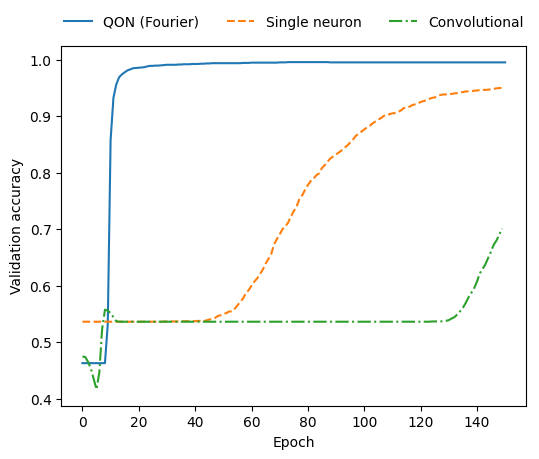

In [ ]:
fig, ax1 = plt.subplots(figsize=(6, 5.5))

# Main plot
ax1.plot(test_accuracy_history, linestyle = '-', \
         label = 'QON (Fourier)')

ax1.plot(dense_history.history['val_accuracy'], linestyle = '--', \
         label = 'Single neuron')

ax1.plot(conv_history.history['val_accuracy'], linestyle = '-.', \
         label = 'Convolutional')

ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation accuracy')

pos = ax1.get_position()
ax1.set_position([pos.x0, pos.y0, pos.width, pos.height * 0.85])
ax1.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=3,
    frameon=False,
)

plt.show()

In [ ]:
# Quantum optical neuron history
np.save('output/data/MNISTfourier_OQPloss.npy', test_loss_history)
np.save('output/data/MNISTfourier_OQPacc.npy', test_accuracy_history)

# Single neuron history
np.save('output/data/MNISTfourier_MLPloss.npy', \
          np.array(dense_history.history['val_loss']))
np.save('output/data/MNISTfourier_MLPacc.npy', \
          np.array(dense_history.history['val_accuracy']))

# Convolutional network history
np.save('output/data/MNISTfourier_CONVloss.npy', \
          np.array(conv_history.history['val_loss']))
np.save('output/data/MNISTfourier_CONVacc.npy', \
          np.array(conv_history.history['val_accuracy']))